# Multi-Agent Research Assistant with LangGraph
#### Authored by Dr. Tiziana Ligorio for *AI Agents - CSCI 395.32* taught at Hunter College of The City University of New York

In this tutorial we build a research assistant that answers **comparison questions** from the scientific literature on arXiv: **questions that ask how several methods, techniques, or approaches compare**. Each approach can be researched independently, which is one situation when splitting work across agents pays off. A single agent would run all the searches one after another, and every abstract it read would pile up in one context. Instead, our system:

1. **Plans:** a lead step splits the question into one brief per approach.
2. **Researches in parallel:** one research subagent per approach searches arXiv in its own context, at the same time as the others, and returns one row of a comparison table.
3. **Checks:** plain code removes any citation that did not come from that researcher's own searches, such as a paper the model made up or remembered from training. If an approach is left with no papers, its researcher tries again.
4. **Writes:** one step reads all the rows and writes a short summary under the table.

We build the system with **LangGraph** (the focus of this tutorial), a framework for **connecting agents and functions into a graph that shares state**. LangGraph works together with **LangChain**, which we used in the ReAct tutorial. LangGraph *runs* the graph: its state, its steps, and which node runs next. LangChain provides **the *pieces* that go inside the nodes**: models, tools, structured output, middleware, and the ready-made ReAct agent `create_agent`. In fact, `create_agent` returns a small LangGraph graph, so the ReAct agents we built were already running on LangGraph. Here we write our own graph, and some of its nodes are `create_agent` agents.

## What you will learn

1. When a task justifies more than one agent, and how to measure what the split costs against a single-agent baseline.
2. How to build a LangGraph graph: shared state, reducers, nodes, edges, conditional edges, and parallel branches with `Send`.
3. How to use agents as nodes: research **subagents** built with `create_agent`, **each with its own brief, tool, and isolated context**.
4. How to read the trace of a parallel run, and how to compare the system with a single agent.

# 1. Installs and Imports

In [1]:
%%capture
!pip install langchain langchain-openai langgraph arxiv python-dotenv

`%%capture` hides the pip install output to keep the notebook clean. If you are running locally, skip this cell: `uv sync` installs the same packages from `pyproject.toml` (see `SETUP.md`).

In [2]:
# Standard library
import os
import re
import json
import operator
import threading
import time
from collections import Counter
from pathlib import Path

# Framework packages (LangChain, LangGraph, arXiv) are imported in the
# sections where we first use them, so you can see what each part needs.

# 2. Setup your API Key

## Step 1 — Get an OpenRouter API key

**OpenRouter** provides access to models from different vendors through one API. This is the only key the tutorial needs.

1. Go to https://openrouter.ai

2. Sign in (or create an account if you don't have one)

3. Once logged in, navigate to https://openrouter.ai/settings/keys

4. Click **Create Key**

5. Give the key a name, e.g. `colab-multiagent-langgraph`

6. Copy the key immediately (you won't be able to see it again)

**Important: Treat this key like a password. Do not share it, paste it into notebooks, or commit it to GitHub.**

## Step 2 — Store your API key

### If running in Google Colab

1. On the left sidebar, click 🔑 **Secrets**.
2. Add a new secret named `OPENROUTER_API_KEY` with your key as the value.
3. Toggle the switch to give the notebook access to the secret.

### If running locally

Create a `.env` file in the project folder containing:

```text
OPENROUTER_API_KEY=your_openrouter_key_here
```

Make sure `.env` is listed in `.gitignore`.

## Load the API Key

### In Colab:

Uncomment and run the cell below if you're using Google Colab.

In [3]:
# Uncomment the lines below if running in Google Colab
# from google.colab import userdata
# os.environ["OPENROUTER_API_KEY"] = userdata.get("OPENROUTER_API_KEY")
# print("API key loaded from Colab Secrets")

### Locally:

Run the cell below if you're running locally with a `.env` file.

In [4]:
# Load the API key from .env file if running locally
from dotenv import load_dotenv
load_dotenv()
print("Environment loaded from .env file")

Environment loaded from .env file


In [5]:
# Check that the key is available (without printing it)
if not os.getenv("OPENROUTER_API_KEY"):
    raise RuntimeError(
        "Missing OPENROUTER_API_KEY. Check Colab Secrets or your local .env file."
    )
print("OPENROUTER_API_KEY is available.")

OPENROUTER_API_KEY is available.


## Choose the model

We use `openai/gpt-4.1-mini` through OpenRouter: a small, inexpensive model that is reliable at tool calling and structured output. Every part of the system uses the same model, so the differences between agents come from their prompts, tools, and context, not from the model.

We set the **temperature to 0** so the model makes nearly the same choices for the same input. That makes a run easier to debug and the baseline comparison fairer. (Outputs can still vary slightly from run to run.)

LangChain's `ChatOpenAI` wrapper talks to any OpenAI-compatible API, so we point it at OpenRouter.

In [6]:
from langchain_openai import ChatOpenAI

OPENROUTER_BASE_URL = "https://openrouter.ai/api/v1"
MODEL = "openai/gpt-4.1-mini"
TEMPERATURE = 0

model = ChatOpenAI(
    model=MODEL,
    temperature=TEMPERATURE,
    base_url=OPENROUTER_BASE_URL,
    api_key=os.getenv("OPENROUTER_API_KEY"),
)

print(f"Model: {MODEL} (temperature {TEMPERATURE})")

Model: openai/gpt-4.1-mini (temperature 0)


# 3. The Demo Question and the Search Tool

We demonstrate the system on one comparison question with five parts:

In [7]:
QUESTION = (
    "How do astronomers detect exoplanets? Compare the transit, radial velocity, "
    "direct imaging, gravitational microlensing, and astrometry methods."
)

## The arXiv search tool

Every agent in this tutorial finds papers through the same tool, `search_arxiv`. It queries [arXiv](https://arxiv.org), a free archive of scientific papers, through the `arxiv` Python package.

* **One shared client.** arXiv asks clients to wait about 3 seconds between requests, and the client enforces that wait. If a request fails, the client retries it once.
* **A lock.** Later, several agents will search at the same time. Without the lock their requests would reach arXiv at the same moment, and arXiv asks for one request at a time. The lock makes searches take turns. Agents that run in parallel still share their tools' limits.
* **A cache.** Every result is saved in `arxiv_cache.json`. A search that has run before returns its saved result instantly, without contacting arXiv. Reruns are fast, and the notebook keeps working when arXiv is limiting requests. If the file is missing, the cache starts empty.
* **Small results.** The tool returns at most 5 compact records: title, year, URL, and the first 600 characters of the abstract. Every result a tool returns ends up in an agent's context, so small results keep every context small.
* **Readable errors.** If arXiv fails, the tool returns a short message with the reason (for example `HTTP 429` when arXiv is limiting requests), which the model can read and react to, instead of crashing the run.

Abstracts are text written by people outside our system. The agents read them as data, but nothing guarantees they contain only what we expect.

In [8]:
import arxiv
from langchain.tools import tool

MAX_RESULTS = 5       # papers per search
ABSTRACT_CHARS = 600  # how much of each abstract the model sees

# page_size: ask arXiv for only the results we keep (the default is 100)
arxiv_client = arxiv.Client(page_size=MAX_RESULTS, delay_seconds=3, num_retries=1)
search_lock = threading.Lock()   # one arXiv request at a time

CACHE_FILE = Path("arxiv_cache.json")
try:
    search_cache = json.loads(CACHE_FILE.read_text())
except (FileNotFoundError, json.JSONDecodeError):
    search_cache = {}

@tool
def search_arxiv(query: str) -> list[dict] | str:
    """Search arXiv for scientific papers matching a short keyword query,
    e.g. "spectroscopy stellar wobble". Returns up to 5 papers, each with
    its title, year, url, and the start of its abstract."""
    key = " ".join(query.lower().split())   # same words, same cache entry

    with search_lock:
        if key in search_cache:
            return search_cache[key]

        search = arxiv.Search(
            query=query,
            max_results=MAX_RESULTS,
            sort_by=arxiv.SortCriterion.Relevance,
        )
        try:
            results = list(arxiv_client.results(search))
        except Exception as e:
            return f"arXiv search failed: {e}. Try again later or use a different query."

        papers = [
            {
                "title": r.title,
                "year": r.published.year,
                "url": r.entry_id,
                "abstract": r.summary[:ABSTRACT_CHARS],
            }
            for r in results
        ]
        search_cache[key] = papers
        CACHE_FILE.write_text(json.dumps(search_cache, indent=1))

    return papers

print(f"{len(search_cache)} searches in the cache")

33 searches in the cache


Test the tool directly before giving it to an agent:

In [9]:
results = search_arxiv.invoke({"query": "exoplanet transit photometry"})

if isinstance(results, str):   # the error message
    print(results)
else:
    for paper in results:
        print(paper["year"], paper["title"])

2026 Transit Photometry and Ephemeris Refinement of WASP-12 b Using TESS Data
2023 Enabling Exoplanet Demographics Studies with Standardized Exoplanet Survey Meta-Data
2011 The CoRoT Exoplanet program : status & results
2015 Characterization of transiting exoplanets by way of differential photometry
2022 Photometry and transit modelling of exoplanet WASP-140b


# 4. A Single-Agent Baseline

Before building several agents, we build **one**. It gets the same model, the same tool, the same instructions, and the same answer format the multi-agent system will use. The baseline is what the multi-agent system has to beat: if one agent does the job as well, for less, we should keep one agent.

## The answer format

The answer is a **comparison table** with one row per approach. Each row says how the approach works, its main strength, and its main limitation, each in one sentence, and cites up to three supporting papers from the searches.

In code, we describe the answer as Pydantic models (Recall, these are Python classes that declare named, typed fields: Pydantic checks that data has those fields and types, and LangChain uses them to tell the model the exact shape of its answer):

* `Comparison` is the whole table: a list of rows.
* `ApproachFinding` is one row: the approach, the three one-sentence fields, and its papers.
* `Paper` is one citation: the paper's title, year, and URL.

The `Field` descriptions are instructions the model reads. The multi-agent system reuses these models, and adds a short summary under the table (Section 6).

In [10]:
from pydantic import BaseModel, Field

class Paper(BaseModel):
    title: str
    year: int
    url: str = Field(description="The paper's arXiv URL, copied exactly from a search result.")

class ApproachFinding(BaseModel):
    approach: str = Field(description="The name of the approach.")
    how_it_works: str = Field(description="One sentence: how the approach works.")
    strength: str = Field(description="One sentence: its main advantage.")
    limitation: str = Field(description="One sentence: its main limitation.")
    papers: list[Paper] = Field(description="Up to 3 supporting papers from the search results.")

class Comparison(BaseModel):
    rows: list[ApproachFinding] = Field(description="One row per approach in the question.")

`show_table` displays the rows as a table. Each paper appears as a link labeled with its year, so the table stays short. Before using it, we test it on two sample rows.

In [11]:
from IPython.display import Markdown, display

def show_table(rows):
    """Display a list of ApproachFinding rows as a Markdown table."""
    def cell(text):
        return text.replace("|", "/")   # a "|" would break the table

    lines = [
        "| Approach | How it works | Strength | Limitation | Papers |",
        "|---|---|---|---|---|",
    ]
    for r in rows:
        papers = " ".join(f"[{p.year}]({p.url})" for p in r.papers)
        lines.append(
            f"| {cell(r.approach)} | {cell(r.how_it_works)} | {cell(r.strength)} "
            f"| {cell(r.limitation)} | {papers} |"
        )
    display(Markdown("\n".join(lines)))

In [37]:
# Two sample rows (made-up papers) to check how show_table displays a table
sample_rows = [
    ApproachFinding(
        approach="Transit",
        how_it_works="Measures the small dip in a star's brightness when a planet passes in front of it.",
        strength="Gives the planet's size and can watch many stars at once.",
        limitation="Only sees planets whose orbits line up edge-on with us.",
        papers=[Paper(title="Sample transit paper", year=2021, url="https://arxiv.org/abs/0000.00001")],
    ),
    ApproachFinding(
        approach="Radial velocity",
        how_it_works="Measures the star's wobble from shifts in its spectral lines.",
        strength="Gives a lower bound on the planet's mass.",
        limitation="Struggles with small planets and active stars.",
        papers=[
            Paper(title="Sample RV paper", year=2019, url="https://arxiv.org/abs/0000.00002"),
            Paper(title="Another sample RV paper", year=2023, url="https://arxiv.org/abs/0000.00003"),
        ],
    ),
]
show_table(sample_rows)

| Approach | How it works | Strength | Limitation | Papers |
|---|---|---|---|---|
| Transit | Measures the small dip in a star's brightness when a planet passes in front of it. | Gives the planet's size and can watch many stars at once. | Only sees planets whose orbits line up edge-on with us. | [2021](https://arxiv.org/abs/0000.00001) |
| Radial velocity | Measures the star's wobble from shifts in its spectral lines. | Gives a lower bound on the planet's mass. | Struggles with small planets and active stars. | [2019](https://arxiv.org/abs/0000.00002) [2023](https://arxiv.org/abs/0000.00003) |

## The baseline agent

The agent is a ReAct agent built with `create_agent`, as in the ReAct tutorial. `create_agent` builds it as a small LangGraph graph with two nodes. The **model** node calls the LLM. The **tools** node runs the tool calls the model asked for. The two nodes call each other in a loop until the model answers without asking for a tool. Section 5 explains LangGraph in detail; for this section, that loop is all you need. `response_format=Comparison` makes the agent return the table as a `Comparison` object.

Its instructions ask for **depth**: for each approach, three searches with different queries, then the three papers most specifically about that approach. `ToolCallLimitMiddleware` caps it at **15 searches**: three for each of up to five approaches. The multi-agent system gets exactly the same instructions and budget, so the comparison is fair.

In [12]:
from langchain.agents import create_agent
from langchain.agents.middleware import ToolCallLimitMiddleware

SEARCHES_PER_APPROACH = 3
MAX_APPROACHES = 5        # a question may compare at most five approaches
MAX_SEARCHES = SEARCHES_PER_APPROACH * MAX_APPROACHES

BASELINE_PROMPT = f"""You answer comparison questions using papers from arXiv.
The question compares at most {MAX_APPROACHES} approaches.
For EACH approach in the question, run {SEARCHES_PER_APPROACH} searches with different short keyword queries
(for example the approach's name, its key instruments or missions, and its main challenge).
Then fill in one row per approach: how it works, its main strength, and its main limitation,
each in one sentence, and the 3 papers most specifically about that approach.
Only cite papers that appeared in your search results, and copy their URLs exactly.
You can run at most {MAX_SEARCHES} searches in total."""

baseline_agent = create_agent(
    model,
    tools=[search_arxiv],
    system_prompt=BASELINE_PROMPT,
    response_format=Comparison,
    middleware=[ToolCallLimitMiddleware(run_limit=MAX_SEARCHES)],
)

**The prompt names the content; `Comparison` sets the format.** The prompt's last lines only say what each row should contain: how the approach works, its strength, its limitation, and its papers. They don't describe the format: no JSON, no field names, no "return a list of…".

The format comes from `response_format=Comparison`. `create_agent` sends the `Comparison` schema to the model. The schema covers its fields, their types, and their `Field` descriptions. When the agent finishes, **Pydantic checks the answer against that schema**. The answer must be a list of `ApproachFinding` rows. Each row needs its four text fields and a list of papers, and each paper needs a title, a whole-number year, and a URL. An answer that doesn't fit never comes back as a `Comparison`: LangChain either asks the model to fix it or raises an error. The format is enforced in code, outside the prompt. We never describe it in words, and we never parse the model's text ourselves. The answer arrives as a `Comparison` object in `baseline_result["structured_response"]`.

Pydantic checks shape and types, not content. "One sentence" and "3 papers" are instructions the model reads, in the prompt and in the `Field` descriptions. Nothing in code checks them.

Run the baseline on the demo question and time it. (A new search waits about 3 seconds for arXiv; a search already in the cache returns instantly.)

LangGraph runs the graph in **steps**: here, each run of the model node or the tools node is one step. By default it stops a run after 25 steps, a guard against agents that loop forever. Each search round takes 2 steps (model, then tools), so 15 searches can need more than 30 steps. `recursion_limit` raises the limit to 60. The search budget itself still comes from `ToolCallLimitMiddleware`. Middleware limits what the agent does (model calls and tool calls); `recursion_limit` is LangGraph's own limit on steps, and raising one does not raise the other. In the ReAct tutorial the agent made at most 8 model calls, about 16 steps, so the default limit was never reached.

In [13]:
start = time.perf_counter()
baseline_result = baseline_agent.invoke(
    {"messages": [{"role": "user", "content": QUESTION}]},
    config={"recursion_limit": 60},   # each search round is 2 graph steps; the default limit is 25
)
baseline_seconds = time.perf_counter() - start

baseline_answer = baseline_result["structured_response"]
show_table(baseline_answer.rows)

| Approach | How it works | Strength | Limitation | Papers |
|---|---|---|---|---|
| Transit method | Detects exoplanets by measuring the dip in a star's brightness when a planet passes in front of it, blocking some light. | Highly successful with a rich set of parameters obtainable, especially when combined with radial velocity data. | Requires precise alignment of the planet's orbit with our line of sight, limiting detection probability. | [2018](http://arxiv.org/abs/1803.07867v2) [2010](http://arxiv.org/abs/1012.2286v1) [2010](http://arxiv.org/abs/1009.1738v2) |
| Radial velocity method | Measures the star's Doppler shifts caused by gravitational tugs from orbiting planets, revealing their presence. | Can detect planets regardless of orbital inclination and provides planet mass estimates. | Limited by stellar activity noise and requires high-precision spectroscopy. | [2011](http://arxiv.org/abs/1101.0463v1) [2010](http://arxiv.org/abs/1009.1738v2) [2026](http://arxiv.org/abs/2609.29378v2) |
| Direct imaging | Captures images of exoplanets by blocking out the host star's light to reveal faint planetary companions. | Allows direct study of planet atmospheres and orbits without relying on indirect effects. | Challenging due to extreme brightness contrast and requires advanced instruments and post-processing. | [2022](http://arxiv.org/abs/2205.05696v3) [2018](http://arxiv.org/abs/1807.05136v1) [2025](http://arxiv.org/abs/2508.14508v2) |
| Gravitational microlensing | Detects planets by observing the magnification of a background star's light caused by the gravitational field of a foreground star-planet system. | Sensitive to low-mass planets at several AU and free-floating planets not orbiting stars. | Events are rare, unpredictable, and typically non-repeatable, limiting follow-up studies. | [2023](http://arxiv.org/abs/2310.07502v2) [2008](http://arxiv.org/abs/0811.0441v1) [2009](http://arxiv.org/abs/0902.1761v1) |
| Astrometry | Measures precise changes in a star's position on the sky caused by the gravitational pull of orbiting planets. | Can determine true planet masses and orbits without inclination ambiguity. | Requires extremely high positional precision, challenging for distant or faint stars. | [2010](http://arxiv.org/abs/1012.3346v1) [2010](http://arxiv.org/abs/1009.1738v2) [2013](http://arxiv.org/abs/1304.0373v1) |

## What did the baseline do?

We write three small helpers to read an agent's messages:

* `search_queries` lists the queries the agent searched for.
* `found_urls` lists the URLs its searches returned.
* `usage_stats` counts model calls, searches, distinct papers found, and tokens. It also reports the **largest context**: the most input tokens any single model call had to read.

In [14]:
from langchain_core.messages import AIMessage, ToolMessage

def search_queries(messages):
    """The queries an agent passed to search_arxiv."""
    return [
        call["args"].get("query", "")
        for m in messages if isinstance(m, AIMessage)
        for call in m.tool_calls if call["name"] == "search_arxiv"
    ]

def found_urls(messages):
    """The URLs that an agent's searches returned."""
    urls = []
    for m in messages:
        if isinstance(m, ToolMessage) and m.name == "search_arxiv":
            try:
                urls += [paper["url"] for paper in json.loads(m.content)]
            except (json.JSONDecodeError, TypeError):
                pass   # an error message, not results
    return urls

def usage_stats(messages):
    """Count model calls, searches, papers found, and tokens in an agent's messages."""
    usage = [m.usage_metadata or {} for m in messages if isinstance(m, AIMessage)]
    return {
        "model calls": len(usage),
        "searches": len(search_queries(messages)),
        "papers found": len(set(found_urls(messages))),
        "largest context": max((u.get("input_tokens", 0) for u in usage), default=0),
        "total tokens": sum(u.get("total_tokens", 0) for u in usage),
    }

baseline_stats = usage_stats(baseline_result["messages"])
baseline_stats["seconds"] = round(baseline_seconds, 1)

for name, value in baseline_stats.items():
    print(f"{name:>16}: {value}")
print("\nQueries:")
for q in search_queries(baseline_result["messages"]):
    print("  ", q)

     model calls: 2
        searches: 5
    papers found: 21
 largest context: 4393
    total tokens: 5949
         seconds: 9.5

Queries:
   transit method exoplanets
   radial velocity method exoplanets
   direct imaging exoplanets
   gravitational microlensing exoplanets
   astrometry exoplanets


Look at the **largest context**. Every search result stays in the agent's conversation, so its last model calls read every abstract found so far, for all five approaches at once: transit papers are still in context while it writes the astrometry row. Also check whether it really ran three searches per approach. We keep `baseline_stats` and `baseline_answer` and compare them with the multi-agent system in Section 9.

# 5. LangGraph: State, Nodes, and Edges

**LangGraph** describes a system as a graph:

* the **state** is a shared data structure that every node can read;
* a **reducer** is a function attached to a state field that says how to combine updates. A plain field is replaced by each update. A field with a reducer combines the old value and the update, for example by adding them. We attach one with `Annotated[type, reducer]`.
* **nodes** are plain Python functions: each reads the state and returns the fields it wants to update;
* **edges** say which node runs next. A **conditional edge** calls a function that decides, at run time, what runs next.

As we saw in Section 4, the baseline agent is already a LangGraph graph: `create_agent` built a small graph with a model node and a tools node that call each other in a loop.

In [15]:
print(type(baseline_agent).__name__)

CompiledStateGraph


## How LangGraph runs a graph

LangGraph runs a graph in **steps**. In each step it runs every node scheduled for that step, merges their updates into the state, and then follows the edges out of those nodes to decide what runs in the next step. Nodes in the same step run in parallel. The run ends when an edge leads to `END`.

Before building the research system, here is a toy graph with no model and no tools. Given a list of numbers, it squares each one in parallel and adds up the squares: for `[1, 2, 3]` it computes 1 + 4 + 9 = 14.

<img src="images/toy_state.png" alt="The shared state of the toy graph" title="The shared state of the toy graph" width="700">

*The toy graph's shared state, and which node reads (white arrows) or writes (teal arrows) each field. `fan_out` is not a node: LangGraph calls it after `split` to create one `Send` per number.*

**What we write** (plain Python):

* **`ToyState`**, the state: two fields. `numbers` is a plain field holding the input list. `total` has a reducer, `operator.add`, so the squares are added together instead of replacing each other.
* **`split`**, a node, and the first step. It receives the state, prints the list, and returns no update. It does no work itself; it only gives the graph a point to fan out from. In the research system its counterpart, `plan`, does real work: it writes the briefs.
* **`fan_out`**, a routing function. It is **not a node**: it doesn't run as a step and doesn't update the state. LangGraph calls it right after `split` finishes, to decide what runs next. It returns one `Send` per number.
* **`square`**, a node. Each run receives one number, `{"n": ...}`, and returns its square as an update to `total`.

**What LangGraph provides:**

* `StateGraph(ToyState)` creates a graph builder. `add_node` registers each of our node functions under a name.
* `START` and `END` mark where a run begins and ends. `add_edge(START, "split")` means the run begins with `split`. `add_edge("square", END)` means the run ends after `square`.
* `add_conditional_edges("split", fan_out, ["square"])` means: after `split`, call `fan_out` to decide what runs next. The third argument lists the nodes it may lead to.
* **`Send(node, arg)`**, a class from `langgraph.types`, means "run this node with this input". `fan_out` returns `[Send("square", {"n": 1}), Send("square", {"n": 2}), Send("square", {"n": 3})]`, so LangGraph runs `square` three times in the next step, in parallel.
* `compile()` checks the graph and turns it into something you can run with `invoke`.

A node started by `Send` receives the `Send` input as its argument instead of the state: `square` receives `{"n": 2}`, not the whole `ToyState`. Its return value still updates the shared state. A routing function can return either the name of a node, to go to that node, or a list of `Send` objects, to run a node several times with different inputs.

Each node prints the step it runs in. It reads the step from `config`, LangGraph's dict with information about the current run, which LangGraph passes to any node that has a parameter named `config`.

In [16]:
from typing import Annotated, TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send

class ToyState(TypedDict):
    numbers: list[int]                       # plain field: an update replaces it
    total: Annotated[int, operator.add]      # reducer: updates are added together

def split(state: ToyState, config):
    print(f"step {config['metadata']['langgraph_step']}: split   {state['numbers']}")
    return {}                                # no update; fan_out decides what runs next

def fan_out(state: ToyState):
    """Routing function (not a node): called after split, returns one Send per number."""
    return [Send("square", {"n": n}) for n in state["numbers"]]

def square(task: dict, config):
    print(f"step {config['metadata']['langgraph_step']}: square  {task}")
    return {"total": task["n"] ** 2}

toy_builder = StateGraph(ToyState)
toy_builder.add_node("split", split)
toy_builder.add_node("square", square)
toy_builder.add_edge(START, "split")
toy_builder.add_conditional_edges("split", fan_out, ["square"])
toy_builder.add_edge("square", END)
toy_graph = toy_builder.compile()

In [17]:
result = toy_graph.invoke({"numbers": [1, 2, 3], "total": 0})
print(result)

step 1: split   [1, 2, 3]
step 2: square  {'n': 1}
step 2: square  {'n': 2}
step 2: square  {'n': 3}
{'numbers': [1, 2, 3], 'total': 14}


Read the output:

* `split` ran in step 1. The three runs of `square` all ran in **step 2**, in parallel, each with its own input from `Send`.
* Each run returned `{"total": n * n}`. The reducer added the three updates to the starting 0: 1 + 4 + 9 = 14. Without the reducer, LangGraph would stop with an error, because three nodes updated the same plain field in the same step.
* The graph ended after step 2, because the edge out of `square` leads to `END`.

The research system works the same way: `plan` plays the role of `split`, `research` plays the role of `square` with a research agent instead of arithmetic, and the reducers merge the researchers' results.

Our multi-agent system is a bigger graph whose nodes call agents like that one:

```
START → plan → research ×5 (in parallel) → check → write → END
                    ↑                        │
                    └── retry once ──────────┘  (if an approach is left with no papers)
```

1. **plan** splits the question into one brief per approach.
2. **research** runs once per brief, all at the same time. Each run is a subagent with its own context: it sees only its own brief and its own search results.
3. **check** is plain code. It removes any citation that did not come from that researcher's own searches. If an approach is left with no papers, its researcher tries again, once.
4. **write** reads all the rows and writes a short summary under the table.

## The plan's output: briefs

Delegating means writing a brief: the researcher will know nothing except what the brief tells it. Our brief names the approach and says, in one sentence, what to find out about it.

In [18]:
class Brief(BaseModel):
    approach: str = Field(description="The name of one approach the question asks about.")
    focus: str = Field(description="One sentence: what the researcher should find out about it.")

class Plan(BaseModel):
    briefs: list[Brief] = Field(description="One brief per approach the question names.")

## The shared state

`ResearchState` lists every field in the state. When a node returns `{"field": value}`, LangGraph merges that update into the state:

* For a plain field, the new value **replaces** the old one.
* For a field declared with `Annotated[type, reducer]`, LangGraph **combines** the old and new values with the reducer.

Reducers matter because of parallelism. Five researchers finish in the same step, and each returns its own `findings`. With no reducer, LangGraph would not know which of the five updates to keep and would stop with an error. Our reducers:

* `operator.or_` merges dictionaries. `findings` and `sources` are keyed by approach, so each researcher adds its own entry, and a retry replaces only its own approach.
* `operator.add` appends lists and adds numbers. Every node adds one record to `trace`, and `removed` counts the citations removed over the whole run.

In [ ]:
from typing import Annotated, TypedDict

class ResearchState(TypedDict):
    question: str
    briefs: list[Brief]                                              # written by plan
    findings: Annotated[dict[str, ApproachFinding], operator.or_]    # one row per approach -
    sources: Annotated[dict[str, list[str]], operator.or_]           # URLs each researcher's searches returned
    retry: list[str]                                                 # approaches left with no papers
    checks: int                                                      # how many times check has run
    removed: Annotated[int, operator.add]                            # citations removed by check
    summary: str                                                     # the short summary, written by write
    trace: Annotated[list[dict], operator.add]                       # one record per node run

<img src="images/shared_state.png" alt="The shared state of the research system" title="The shared state of the research system" width="80%">

*The shared state, and which node reads (white arrows) or writes (teal arrows) each field. The picture is simplified: `write` also reads `question` and `briefs`; `after_check`, the edge after `check`, reads `retry` and `checks` to decide whether to send an approach back (the dashed arrow); and `removed` and `trace` are left out, although `check` adds to `removed` and every node adds a record to `trace`. The researchers do not read the state directly: they receive the question and their brief as a task through `Send`.*

# 6. The Nodes

Each node is a function `(state, config) -> dict`. Besides its real work, every node adds one **trace record** to the state: its name, the approach it worked on, when it started and ended, and what it used. `config` carries LangGraph's run information, including the **step** number. Nodes that run in parallel share a step. When we call a node by hand to test it, there is no step, so the record shows `-`.

In [ ]:
from langchain_core.runnables import RunnableConfig

def trace_record(node, start, config, approach="", messages=()):
    """One row of the trace: what a node did, when, and what it used."""
    stats = usage_stats(messages) #same as what we used for the baseline_agent
    return {
        "step": (config or {}).get("metadata", {}).get("langgraph_step", "-"),
        "node": node,
        "approach": approach,
        "start": start,
        "end": time.perf_counter(),
        "searches": stats["searches"],
        "papers found": stats["papers found"],
        "largest context": stats["largest context"],
        "tokens": stats["total tokens"],
        "queries": search_queries(messages),
    }

## Node 1: `plan`

The lead step is one model call with **structured output**: `with_structured_output(Plan)` makes the model return a `Plan` object. With `include_raw=True` we also get the raw model message, which carries the token counts for the trace.

In [ ]:
PLAN_PROMPT = f"""You plan research for a comparison question.
Write one brief for each approach the question names, at most {MAX_APPROACHES}. Do not add approaches the question does not name.
In each brief, say in one sentence what the researcher should find out about that approach."""

planner = model.with_structured_output(Plan, include_raw=True) #include_raw=True so the trace can extract the stats

def plan(state: ResearchState, config: RunnableConfig = None) -> dict:
    start = time.perf_counter()
    out = planner.invoke([
        {"role": "system", "content": PLAN_PROMPT},
        {"role": "user", "content": state["question"]},
    ])
    briefs = out["parsed"].briefs[:MAX_APPROACHES]   #out["parsed"] is the answer as a Plan object, never more researchers than the budget allows
    print(f"plan: {len(briefs)} briefs: {', '.join(b.approach for b in briefs)}")
    return {
        "briefs": briefs,
        "trace": [trace_record("plan", start, config, messages=[out["raw"]])],
    }

Test the node by hand, with a state that holds only the question:

In [22]:
plan_update = plan({"question": QUESTION})
for brief in plan_update["briefs"]:
    print(f"- {brief.approach}: {brief.focus}")

plan: 5 briefs: transit, radial velocity, direct imaging, gravitational microlensing, astrometry
- transit: Determine how the transit method detects exoplanets by measuring the dip in a star's brightness as a planet passes in front of it.
- radial velocity: Understand how the radial velocity method detects exoplanets by observing the star's spectrum shifts caused by gravitational tugs from orbiting planets.
- direct imaging: Explore how direct imaging captures actual pictures of exoplanets by blocking out starlight to reveal faint planets nearby.
- gravitational microlensing: Investigate how gravitational microlensing detects exoplanets through the bending and magnification of light from a background star caused by a planet's gravity.
- astrometry: Examine how astrometry detects exoplanets by precisely measuring the star's position changes due to the gravitational influence of orbiting planets.


## Node 2: `research` (the subagent)

The researcher is a ReAct agent built with `create_agent`, like the baseline, with the same tool and the same depth instructions, but for **one** approach: three searches, then one row. `ToolCallLimitMiddleware` caps it at three searches and `response_format=ApproachFinding` makes it return one row.

We define the agent once. Every call to `research` starts it with a fresh conversation that contains only the brief, so each researcher has its own **isolated context**: it never sees the other approaches' searches.

The **node receives a task** rather than the whole state: **a dict with the question, one brief, and, on a retry, a note**. The routing functions in Section 7 create the tasks with `Send`. It returns three updates: its row, the URLs its searches returned (for `check`), and its trace record.

In [23]:
RESEARCHER_PROMPT = f"""You research ONE approach of a comparison question, using arXiv.
Run {SEARCHES_PER_APPROACH} searches with different short keyword queries
(for example the approach's name, its key instruments or missions, and its main challenge).
Then fill in the row: how it works, its main strength, and its main limitation,
each in one sentence, and the 3 papers most specifically about this approach.
Only cite papers that appeared in your search results, and copy their URLs exactly.
Stay on your approach: other researchers cover the others."""

researcher = create_agent(
    model,
    tools=[search_arxiv],
    system_prompt=RESEARCHER_PROMPT,
    response_format=ApproachFinding,
    middleware=[ToolCallLimitMiddleware(run_limit=SEARCHES_PER_APPROACH)],
)

def write_brief(task):
    """The first and only message the researcher receives."""
    brief = task["brief"]
    text = (
        f"Question: {task['question']}\n"
        f"Your approach: {brief.approach}\n"
        f"What to find out: {brief.focus}"
    )
    if task.get("note"):
        text += f"\nNote: {task['note']}"
    return text

def research(task: dict, config: RunnableConfig = None) -> dict:
    start = time.perf_counter()
    approach = task["brief"].approach
    result = researcher.invoke({"messages": [{"role": "user", "content": write_brief(task)}]})

    # Use the planner's name for the approach, so every update uses the same key
    finding = result["structured_response"].model_copy(update={"approach": approach})
    messages = result["messages"]
    record = trace_record("research", start, config, approach, messages)
    print(f"research [{approach}]: {record['searches']} searches, {len(finding.papers)} papers cited")
    return {
        "findings": {approach: finding},
        "sources": {approach: found_urls(messages)},
        "trace": [record],
    }

Test one researcher by hand on the first brief. This is everything the researcher saw from the outside:

In [24]:
first_task = {"question": QUESTION, "brief": plan_update["briefs"][0]}
print(write_brief(first_task))

Question: How do astronomers detect exoplanets? Compare the transit, radial velocity, direct imaging, gravitational microlensing, and astrometry methods.
Your approach: transit
What to find out: Determine how the transit method detects exoplanets by measuring the dip in a star's brightness as a planet passes in front of it.


In [25]:
research_update = research(first_task)
show_table(research_update["findings"].values())
print("Queries:", research_update["trace"][0]["queries"])

research [transit]: 3 searches, 3 papers cited


| Approach | How it works | Strength | Limitation | Papers |
|---|---|---|---|---|
| transit | The transit method detects exoplanets by measuring the periodic dip in a star's brightness as a planet passes in front of it, blocking some of the star's light. | Its main advantage is the ability to provide a rich set of parameters about the planet, especially when combined with radial velocity data, enabling detailed characterization of the exoplanet. | The method requires the planetary orbit to be aligned such that transits are visible from Earth, which limits the number of detectable planets and can lead to false positives from other astrophysical phenomena. | [2018](http://arxiv.org/abs/1803.07867v2) [2010](http://arxiv.org/abs/1012.2286v1) [2015](http://arxiv.org/abs/1509.01238v1) |

Queries: ['transit method exoplanets', 'transit photometry exoplanet detection', 'transit method challenges exoplanets']


## Node 3: `check`

`check` follows a few practices for building reliable agent systems:

* **Verify model output with code wherever you can.**
* **Ground claims in tool results.**
* **Check at the handoff, before results are combined.**
* **Fail safe, and retry with a reason, a bounded number of times.**
* **Keep generating and checking separate.**

It verifies where each citation came from, not whether the paper is relevant to the approach or whether the row's claims are correct.

For each approach, it keeps only the cited papers that appeared in **that researcher's own** search results, comparing arXiv ids (ignoring the version suffix, so `1105.1887v1` and `1105.1887` match). It removes the rest (fail safe) and lists the approaches left with no papers in `retry, updating checks so that each approach can be retried at most once.

A model can cite a paper it never found, especially when a search fails. A rule in the prompt asks it not to; the check makes sure.

In [26]:
def arxiv_id(url):
    """'http://arxiv.org/abs/1105.1887v1' -> '1105.1887'"""
    return re.sub(r"v\d+$", "", url.strip().rstrip("/").split("/abs/")[-1])

def check(state: ResearchState, config: RunnableConfig = None) -> dict:
    start = time.perf_counter()
    cleaned, retry, removed = {}, [], 0
    for approach, finding in state["findings"].items():
        found = {arxiv_id(url) for url in state["sources"].get(approach, [])}
        kept = [p for p in finding.papers if arxiv_id(p.url) in found]
        removed += len(finding.papers) - len(kept)
        cleaned[approach] = finding.model_copy(update={"papers": kept})
        if not kept:
            retry.append(approach)

    print(f"check: removed {removed} citations not found in the searches"
          + (f"; retry: {', '.join(retry)}" if retry else ""))
    return {
        "findings": cleaned,
        "removed": removed,
        "retry": retry,
        "checks": state.get("checks", 0) + 1,
        "trace": [trace_record("check", start, config)],
    }

## Node 4: `write`

`write` is the only step that needs every approach at once, so it runs once, after all the research. Reading parallelizes well; writing a combined answer does not. It reads the rows (without the papers) and writes a short summary of at most three sentences.

In [27]:
WRITE_PROMPT = """You write a short summary of a comparison table. You get one row per approach.
In at most three sentences, say what each approach is best at and how they complement each other.
Use only the information in the rows."""

def write(state: ResearchState, config: RunnableConfig = None) -> dict:
    start = time.perf_counter()
    rows = [state["findings"][b.approach] for b in state["briefs"]]
    table = "\n".join(
        f"- {r.approach}: {r.how_it_works} Strength: {r.strength} Limitation: {r.limitation}"
        for r in rows
    )
    reply = model.invoke([
        {"role": "system", "content": WRITE_PROMPT},
        {"role": "user", "content": f"Question: {state['question']}\n\nRows:\n{table}"},
    ])
    print("write: short summary written")
    return {"summary": reply.content, "trace": [trace_record("write", start, config, messages=[reply])]}

# 7. Build the Graph

## Parallel branches with `Send`

The research system uses `Send` exactly as the toy graph did.

`fan_out` is the conditional edge after `plan`:

* It returns one `Send("research", task)` per brief, where `task` is `{"question": ..., "brief": ...}`.
* LangGraph runs `research` once per brief, all in the same step, in parallel. Each run receives its own task, not the whole state; that is why `research(task, config)` reads `task["brief"]`.
* The number of researchers comes from the plan at run time: five briefs, five runs.
* A run's result reaches the state only through what `research` returns; the reducers on `findings`, `sources`, and `trace` merge the five updates.
* The next node, `check`, runs only when every `research` run has finished.

`after_check` is the conditional edge after `check`, and it shows both things such a function can return:

* if some approaches were left with no papers and we have not retried yet, a **list of `Send` objects**, one per approach to retry, each task with a note for the researcher;
* otherwise the **name of a node**, `"write"`.

In [28]:
from langgraph.types import Send

MAX_RETRIES = 1

def fan_out(state: ResearchState):
    """After plan: one research task per brief."""
    return [Send("research", {"question": state["question"], "brief": b}) for b in state["briefs"]]

def after_check(state: ResearchState):
    """After check: retry approaches left with no papers (once), otherwise write."""
    if state["retry"] and state["checks"] <= MAX_RETRIES:
        note = "Your previous row cited no paper from your own search results. Cite only papers your searches returned."
        return [
            Send("research", {"question": state["question"], "brief": b, "note": note})
            for b in state["briefs"] if b.approach in state["retry"]
        ]
    return "write"

Test `check` and `after_check` together, without any model. We take the row from the researcher test, then add a second row whose only paper was never found by a search:

In [29]:
real = research_update["findings"]
made_up = ApproachFinding(
    approach="Made-up method",
    how_it_works="-", strength="-", limitation="-",
    papers=[Paper(title="A paper nobody found", year=2020, url="http://arxiv.org/abs/2001.12345v1")],
)
test_state = {
    "question": QUESTION,
    "briefs": [first_task["brief"], Brief(approach="Made-up method", focus="-")],
    "findings": {**real, "Made-up method": made_up},
    "sources": research_update["sources"],   # only the real researcher's URLs
}

check_update = check(test_state)
next_step = after_check({**test_state, **check_update})
print("Next:", next_step if isinstance(next_step, str)
      else [f"research [{s.arg['brief'].approach}]" for s in next_step])

check: removed 1 citations not found in the searches; retry: Made-up method
Next: ['research [Made-up method]']


`check` removed the made-up citation, and `after_check` sent only the made-up approach back to `research`. The real row passed untouched.

Now assemble the graph: add the nodes, then the edges. `add_conditional_edges` takes the node, the function that decides, and the nodes it may lead to.

In [30]:
from langgraph.graph import StateGraph, START, END

builder = StateGraph(ResearchState)
builder.add_node("plan", plan)
builder.add_node("research", research)
builder.add_node("check", check)
builder.add_node("write", write)

builder.add_edge(START, "plan")
builder.add_conditional_edges("plan", fan_out, ["research"])
builder.add_edge("research", "check")
builder.add_conditional_edges("check", after_check, ["research", "write"])
builder.add_edge("write", END)

research_graph = builder.compile()

LangGraph can draw the compiled graph. Dashed arrows are conditional edges. (Drawing the picture uses an online service; without internet access, the cell prints the graph's Mermaid text instead.)

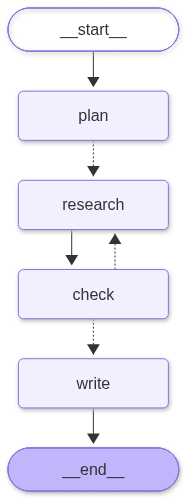

In [31]:
from IPython.display import Image

try:
    display(Image(research_graph.get_graph().draw_mermaid_png()))
except Exception:
    print(research_graph.get_graph().draw_mermaid())

# 8. Run the System

The input is a state that holds only the question. Each node prints one line as it finishes.

In [32]:
start = time.perf_counter()
final = research_graph.invoke({"question": QUESTION})
multi_seconds = time.perf_counter() - start

rows = [final["findings"][b.approach] for b in final["briefs"]]
show_table(rows)
display(Markdown(f"**Short summary:** {final['summary']}"))

plan: 5 briefs: transit, radial velocity, direct imaging, gravitational microlensing, astrometry
research [transit]: 3 searches, 3 papers cited
research [direct imaging]: 3 searches, 3 papers cited
research [radial velocity]: 3 searches, 3 papers cited
research [astrometry]: 3 searches, 3 papers cited
research [gravitational microlensing]: 3 searches, 3 papers cited
check: removed 0 citations not found in the searches
write: bottom line written


| Approach | How it works | Strength | Limitation | Papers |
|---|---|---|---|---|
| transit | The transit method detects exoplanets by measuring the periodic dip in a star's brightness as a planet passes in front of it, blocking some of the star's light. | Its main advantage is the ability to provide a rich set of planetary parameters, including planet size and orbital period, especially when combined with radial velocity data. | Its main limitation is that it requires the planetary orbit to be aligned such that the planet transits the star from our line of sight, which is a relatively rare geometric alignment. | [2018](http://arxiv.org/abs/1803.07867v2) [2015](http://arxiv.org/abs/1509.01238v1) [2026](http://arxiv.org/abs/2601.04484v2) |
| radial velocity | The radial velocity method detects exoplanets by measuring the Doppler shifts in the spectrum of a star caused by the gravitational tug of orbiting planets, which induces periodic changes in the star's velocity along the line of sight. | Its main advantage is the ability to detect planets around stars by precise measurements of stellar motion, enabling the discovery of planets that do not transit their stars and providing estimates of planetary mass. | Its main limitation is sensitivity to stellar activity and noise, which can obscure or mimic the small velocity signals induced by smaller or more distant planets, limiting detection to relatively massive or close-in planets. | [2011](http://arxiv.org/abs/1101.0463v1) [2010](http://arxiv.org/abs/1009.1738v2) [2026](http://arxiv.org/abs/2609.29378v2) |
| direct imaging | Direct imaging captures actual pictures of exoplanets by blocking out the overwhelming starlight using instruments like coronagraphs and adaptive optics, allowing the faint light from the planet to be detected and analyzed. | Its main advantage is that it provides direct visual evidence and allows detailed characterization of exoplanet atmospheres and orbits through spectroscopy and photometry. | The main limitation is the extreme difficulty due to the high contrast ratio between the bright star and the faint planet, requiring advanced technology to suppress starlight and overcome noise such as speckles. | [2022](http://arxiv.org/abs/2205.05696v3) [2018](http://arxiv.org/abs/1807.05136v1) [2025](http://arxiv.org/abs/2508.14508v2) |
| gravitational microlensing | Gravitational microlensing detects exoplanets by observing the bending and magnification of light from a background star caused by the gravitational field of a foreground star and its planet acting as a lens. | It is uniquely sensitive to low-mass planets at several astronomical units from their stars and can detect free-floating planets not bound to any star. | Microlensing events are rare, unpredictable, and typically non-repetitive, making follow-up observations and detailed characterization challenging. | [2023](http://arxiv.org/abs/2310.07502v2) [2008](http://arxiv.org/abs/0811.0441v1) [2009](http://arxiv.org/abs/0902.1761v1) |
| astrometry | Astrometry detects exoplanets by precisely measuring the tiny changes in a star's position in the sky caused by the gravitational pull of orbiting planets, revealing their presence and orbital characteristics. | Its main advantage is the ability to directly measure the planet's mass and orbit inclination without relying on the planet's light, enabling detection of planets in wide orbits and around various types of stars. | The main limitation is the extremely high precision required—microarcsecond-level accuracy—which is challenging to achieve and demands advanced space-based instruments and long-term observations. | [2010](http://arxiv.org/abs/1012.3346v1) [2018](http://arxiv.org/abs/1803.03732v1) [2013](http://arxiv.org/abs/1304.0370v1) |

**Bottom line:** The transit method excels at providing detailed planetary parameters like size and orbital period but requires rare orbital alignments. Radial velocity complements this by detecting planets regardless of transit and estimating mass, though it is limited by stellar noise and favors massive, close-in planets. Direct imaging offers direct visual and atmospheric characterization of exoplanets but demands advanced technology to overcome brightness contrast. Gravitational microlensing uniquely detects low-mass and free-floating planets at wide separations but suffers from rare, unpredictable events with limited follow-up. Astrometry directly measures planet mass and orbit inclination for wide orbits without relying on light but requires extremely precise, long-term observations with advanced instruments. Together, these methods cover a broad range of planet types, orbital distances, and detection challenges, providing a complementary toolkit for exoplanet discovery and study.

## The trace

`show_trace` turns the trace records into a timeline. Times are seconds since the run started.

In [33]:
def show_trace(trace):
    """Display trace records as a timeline table."""
    t0 = min(r["start"] for r in trace)
    lines = [
        "| Step | Node | Approach | Start (s) | End (s) | Searches | Largest context | Tokens |",
        "|---|---|---|---|---|---|---|---|",
    ]
    for r in sorted(trace, key=lambda r: r["start"]):
        lines.append(
            f"| {r['step']} | {r['node']} | {r['approach']} | {r['start'] - t0:.1f} | {r['end'] - t0:.1f} "
            f"| {r['searches']} | {r['largest context']} | {r['tokens']} |"
        )
    display(Markdown("\n".join(lines)))

show_trace(final["trace"])

| Step | Node | Approach | Start (s) | End (s) | Searches | Largest context | Tokens |
|---|---|---|---|---|---|---|---|
| 1 | plan |  | 0.0 | 2.1 | 0 | 206 | 420 |
| 2 | research | transit | 2.1 | 6.5 | 3 | 2940 | 3738 |
| 2 | research | radial velocity | 2.1 | 20.7 | 3 | 3010 | 3821 |
| 2 | research | direct imaging | 2.1 | 10.0 | 3 | 2806 | 3594 |
| 2 | research | gravitational microlensing | 2.1 | 30.9 | 3 | 2880 | 3673 |
| 2 | research | astrometry | 2.1 | 23.9 | 3 | 2898 | 3693 |
| 3 | check |  | 30.9 | 30.9 | 0 | 0 | 0 |
| 4 | write |  | 30.9 | 32.7 | 0 | 660 | 824 |

Read the trace from top to bottom:

* All the `research` rows share **one step number** and their times overlap: LangGraph ran them in parallel.
* `check` starts only after the **slowest** researcher ends. In a parallel step, the slowest branch sets the pace.
* The researchers end at different times because they share one tool: their arXiv searches took turns through the lock. On a rerun, with every search in the cache, they end close together.
* Each researcher's **largest context** holds only its own approach's searches. Compare it with the baseline's in Section 9.
* If `check` sent an approach back, a second `research` row for it appears with a later step number.

What each researcher searched for:

In [34]:
for r in final["trace"]:
    if r["node"] == "research":
        print(f"{r['approach']}: {r['queries']}")

transit: ['transit exoplanet detection', 'transit method exoplanet challenges', 'transit photometry exoplanets']
radial velocity: ['radial velocity exoplanets', 'Doppler shifts exoplanets', 'radial velocity method sensitivity limitations']
direct imaging: ['direct imaging exoplanets', 'coronagraph adaptive optics exoplanets', 'direct imaging exoplanets challenges']
gravitational microlensing: ['gravitational microlensing exoplanets', 'gravitational microlensing light bending', 'gravitational microlensing limitations exoplanets']
astrometry: ['astrometry exoplanets', 'astrometry precision exoplanet detection', 'astrometry challenges exoplanets']


# 9. One Agent or Several?

The same question, the same model, tool, instructions, and search budget. `cited_in_several_rows` counts papers that appear in more than one row: a paper cited for two different methods is usually a general exoplanet paper rather than one about a specific method. For the baseline, citations not from a search are counted against all of its searches; in the multi-agent system, `check` already removed them.

In [35]:
def cited_in_several_rows(rows):
    counts = Counter(arxiv_id(p.url) for r in rows for p in r.papers)
    return sum(1 for n in counts.values() if n > 1)

# Baseline
b_rows = baseline_answer.rows
b_found = {arxiv_id(url) for url in found_urls(baseline_result["messages"])}
baseline_column = {
    "Searches per approach": baseline_stats["searches"] / len(b_rows),
    "Papers found per approach": baseline_stats["papers found"] / len(b_rows),
    "Largest context (tokens)": baseline_stats["largest context"],
    "Total tokens": baseline_stats["total tokens"],
    "Seconds": baseline_stats["seconds"],
    "Citations not from a search": sum(arxiv_id(p.url) not in b_found for r in b_rows for p in r.papers),
    "Papers cited in more than one row": cited_in_several_rows(b_rows),
}

# Multi-agent system
researchers = [r for r in final["trace"] if r["node"] == "research"]
multi_column = {
    "Searches per approach": sum(r["searches"] for r in researchers) / len(rows),
    "Papers found per approach": sum(r["papers found"] for r in researchers) / len(rows),
    "Largest context (tokens)": max(r["largest context"] for r in final["trace"]),
    "Total tokens": sum(r["tokens"] for r in final["trace"]),
    "Seconds": round(multi_seconds, 1),
    "Citations not from a search": final["removed"],
    "Papers cited in more than one row": cited_in_several_rows(rows),
}

lines = ["| | One agent | Multi-agent |", "|---|---|---|"]
for name in baseline_column:
    b, m = baseline_column[name], multi_column[name]
    fmt = (lambda v: f"{v:.1f}") if isinstance(b, float) or isinstance(m, float) else str
    lines.append(f"| {name} | {fmt(b)} | {fmt(m)} |")
display(Markdown("\n".join(lines)))

| | One agent | Multi-agent |
|---|---|---|
| Searches per approach | 1.0 | 3.0 |
| Papers found per approach | 4.2 | 10.4 |
| Largest context (tokens) | 4393 | 3010 |
| Total tokens | 5949 | 19763 |
| Seconds | 9.5 | 32.7 |
| Citations not from a search | 0 | 0 |
| Papers cited in more than one row | 1 | 0 |

Which papers were cited in more than one row?

In [36]:
def show_repeats(name, rows):
    """Print every paper cited in more than one row, with the rows that cite it."""
    cited = {}   # arXiv id -> (title, approaches)
    for r in rows:
        for p in r.papers:
            cited.setdefault(arxiv_id(p.url), (p.title, []))[1].append(r.approach)
    repeats = [(title, approaches) for title, approaches in cited.values() if len(approaches) > 1]
    for title, approaches in repeats:
        print(f'{name}: "{title}" is cited for {", ".join(approaches)}')
    if not repeats:
        print(f"{name}: no repeats")

show_repeats("One agent", b_rows)
show_repeats("Multi-agent", rows)

One agent: "Keplerian Orbits and Dynamics of Exoplanets" is cited for Transit method, Radial velocity method, Astrometry
Multi-agent: no repeats


What to look for:

* **Depth.** Both systems got the same instruction: three searches per approach. Check whether the single agent followed it. With five approaches on its to-do list, a single agent tends to cut corners. Each researcher has one approach and does the whole job.
* **Specific papers.** A paper cited in more than one row is usually a general exoplanet paper, not one about that method. A researcher that searches only for its own method finds papers about that method.
* **Focus.** Each researcher's largest context holds only its own approach, even though it searched more. The single agent's context mixes all five approaches; had it run all 15 searches, it would hold three times as many abstracts.
* **Cost.** The multi-agent system spends more tokens: more searches, five system prompts, a plan, and a short summary. That is the price of the extra depth. Lecture 9's numbers make the same point at a larger scale: compared with a chat, an agent uses about 4× the tokens, and a multi-agent system about 15×.
* **Time.** On a first run, both systems mostly wait for arXiv: the lock makes searches take turns, and the multi-agent system runs more of them. Run Sections 4 and 8 again: every search now comes from the cache, so the seconds show the model calls alone, and in the trace the five researchers take about as long as one.

The split pays off when the parts are **independent** and each needs **real depth**. For a question with one part, or with parts that need each other's results, one agent is the better choice.

# 10. Reflect and Your Turn

1. **A multi-agent system is a graph.** LangGraph describes it with a shared state, nodes that return updates, and edges, some of them conditional. Agents built with `create_agent` are graphs too, so they can run inside a node.
2. **Reducers make parallel updates safe.** Five researchers write `findings` in the same step; `operator.or_` merges their entries by approach.
3. **`Send` creates parallel branches at run time.** The number of researchers comes from the plan, not from the code.
4. **Each subagent has an isolated context.** A researcher sees only its brief and its own results, which keeps its context small and focused. The brief is all it knows, so the brief has to be good.
5. **Plain code checks the agents' work.** `check` needs no model, and it can send work back through a conditional edge.
6. **Splitting has a cost.** More tokens, more moving parts, and shared limits (the lock). Measure against a single agent before choosing.

## Your turn

* **Change the question.** Try a comparison with two approaches, and a question with only one. How many briefs does `plan` write? Run the baseline too: at what size does the split stop paying off?
* **Remove a reducer.** Change `findings` to a plain `dict[str, ApproachFinding]` and run the graph. Read the error: what is LangGraph telling you?
* **Make `check` stricter.** Also send back any approach left with fewer than two papers. Watch the retry in the trace.
* **Add a second source.** Write a tool for another paper database (for example Semantic Scholar or OpenAlex) and give it to the researchers. How should duplicates across sources be handled?
* **Pause after the plan.** Compile the graph with a checkpointer and `interrupt_before=["research"]`, so a person can read and edit the briefs before the researchers start. See the LangGraph documentation on human-in-the-loop.